In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


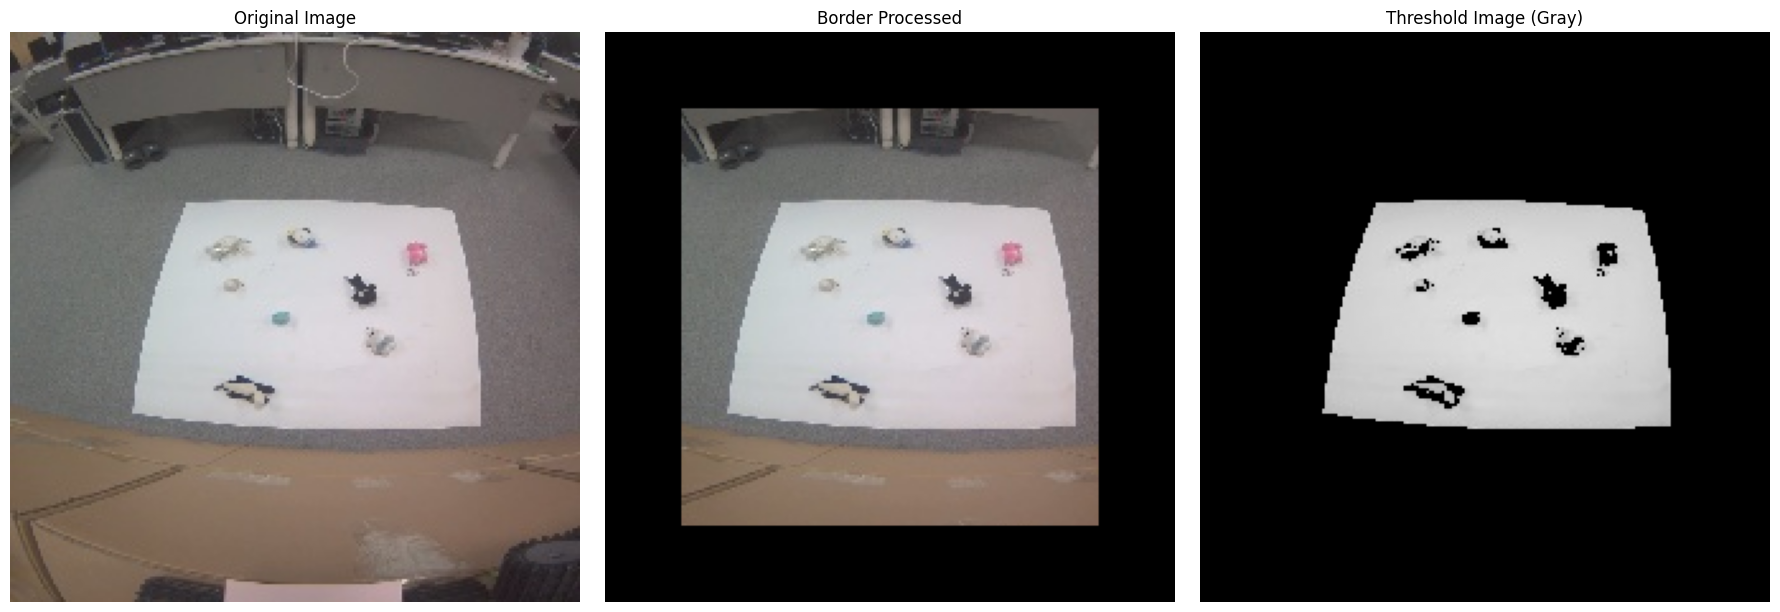

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

file_path = '/content/drive/MyDrive/Colab Notebooks/AGV/image_0000.jpg'
img = cv2.imread(file_path)

# 1. 원본 이미지
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


# 2. crop 이미지
img_processed = img_rgb.copy()
thickness = 30
img_processed[:thickness, :, :] = 0
img_processed[-thickness:, :, :] = 0
img_processed[:, :thickness, :] = 0
img_processed[:, -thickness:, :] = 0

# 3. 그레이스케일 이미지(th값 설정)
gray_processed = cv2.cvtColor(img_processed, cv2.COLOR_RGB2GRAY)
threshold_img = np.where(gray_processed <= 170, 0, gray_processed)

# 4. 출력
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(img_rgb)
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(img_processed)
axes[1].set_title('Border Processed')
axes[1].axis('off')

axes[2].imshow(threshold_img, cmap='gray')  # 그레이스케일 출력을 위해 cmap='gray' 추가
axes[2].set_title('Threshold Image (Gray)')
axes[2].axis('off')

# 레이아웃 정렬 및 출력
plt.tight_layout()
plt.show()

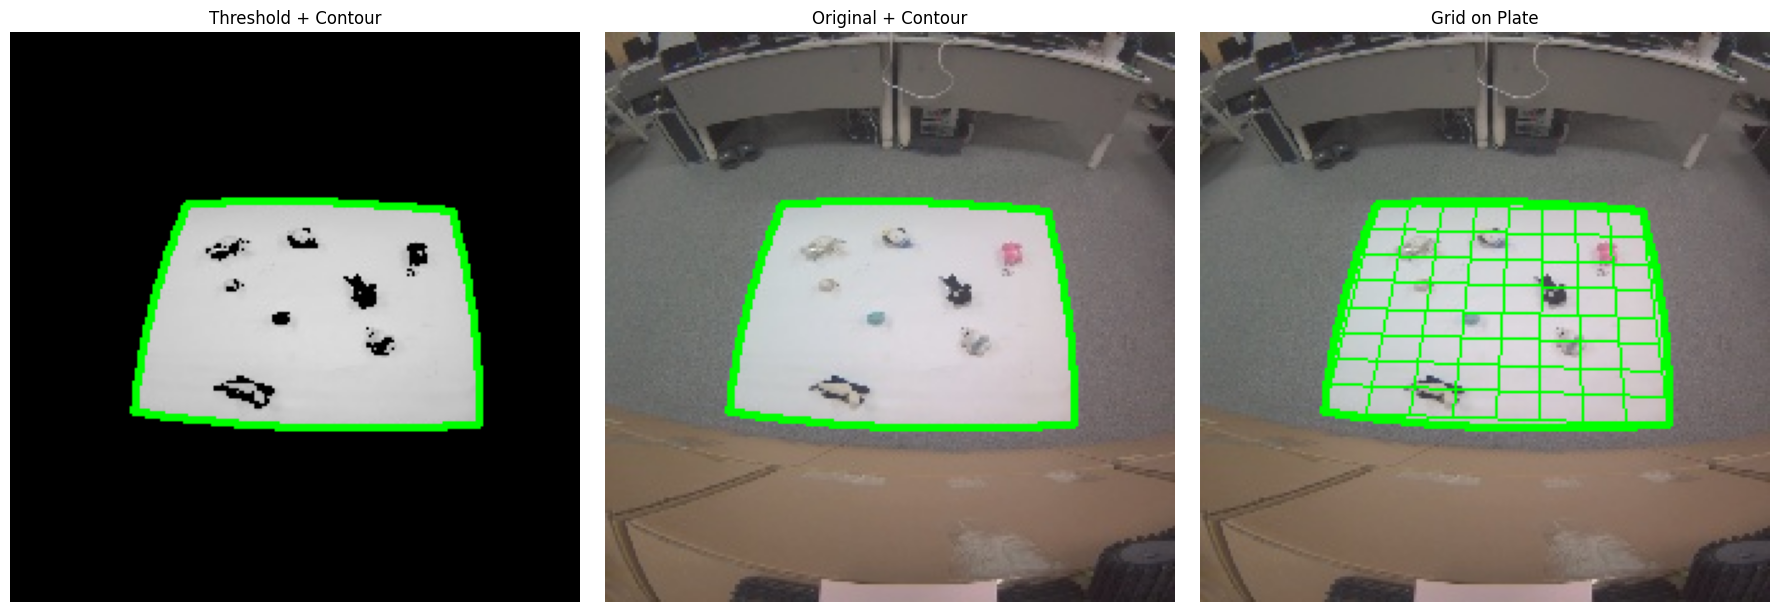

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --- [함수 정의] 판 위에 그리드(격자)를 그리는 함수 ---
def draw_grid_on_plate(img, contour, grid_size=8):
    approx = cv2.approxPolyDP(contour, 0.02 * cv2.arcLength(contour, True), True)
    if len(approx) != 4:
        print("꼭짓점이 4개가 아닙니다.")
        return img.copy(), None # 에러 방지용 빈 값 반환

    pts = approx.reshape(4, 2).astype("float32")
    s = pts.sum(axis=1)
    rect = np.zeros((4, 2), dtype="float32")
    rect[0] = pts[np.argmin(s)]
    rect[2] = pts[np.argmax(s)]
    diff = np.diff(pts, axis=1)
    rect[1] = pts[np.argmin(diff)]
    rect[3] = pts[np.argmax(diff)]

    (tl, tr, br, bl) = rect
    result_img = img.copy()

    # 그리드 그리기 (가로선 및 세로선 보간)
    for i in range(grid_size + 1):
        ratio = i / grid_size

        # 가로선 시작점/끝점 (왼쪽 변과 오른쪽 변 사이)
        start_h = tl + (bl - tl) * ratio
        end_h = tr + (br - tr) * ratio
        cv2.line(result_img, tuple(start_h.astype(int)), tuple(end_h.astype(int)), (0, 255, 0), 1)

        # 세로선 시작점/끝점 (윗변과 아랫변 사이)
        start_v = tl + (tr - tl) * ratio
        end_v = bl + (br - bl) * ratio
        cv2.line(result_img, tuple(start_v.astype(int)), tuple(end_v.astype(int)), (0, 255, 0), 1)

    # 이미지와 꼭짓점 좌표(rect)를 함께 반환
    return result_img, rect


# --- [메인 처리 프로세스] ---

# 1. 윤곽선(Contours) 찾기
contours, _ = cv2.findContours(threshold_img.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

if contours:
    # 가장 면적이 큰 윤곽선 선택
    largest_contour = max(contours, key=cv2.contourArea)

    # [이미지 1] 이진화(Threshold) 영상 위에 윤곽선 그리기
    result_thresh_contour = cv2.cvtColor(threshold_img, cv2.COLOR_GRAY2RGB)
    cv2.drawContours(result_thresh_contour, [largest_contour], -1, (0, 255, 0), 2)

    # [이미지 2] 원본 컬러(RGB) 영상 위에 윤곽선 그리기
    img_contour = img_rgb.copy()
    cv2.drawContours(img_contour, [largest_contour], -1, (0, 255, 0), 2)

    # [이미지 3] 원본 컬러 영상 위에 그리드(격자) 그리기
    # [수정 포인트] 함수가 주는 2개의 반환값(이미지, rect)을 둘 다 받도록 수정했습니다.
    grid_img, rect = draw_grid_on_plate(img_contour, largest_contour, grid_size=8)

    # 시각화 (1행 3열 구조)
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # 첫 번째 칸: 이진화 맵 + 윤곽선
    axes[0].imshow(result_thresh_contour)
    axes[0].set_title('Threshold + Contour')
    axes[0].axis('off')

    # 두 번째 칸: 원본 이미지 + 윤곽선
    axes[1].imshow(img_contour)
    axes[1].set_title('Original + Contour')
    axes[1].axis('off')

    # 세 번째 칸: 원본 이미지 + 윤곽선 + 격자(Grid)
    axes[2].imshow(grid_img)
    axes[2].set_title('Grid on Plate')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

else:
    print("윤곽선을 찾지 못했습니다. 이전 단계의 임계값(Threshold) 설정을 확인해주세요.")